<a href="https://colab.research.google.com/github/athfizh/PemMes26_05_Hafizh/blob/main/JS09/JS09-TugasLab1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---

# **Hierarchical Clustering - Tugas Lab 1**

---

> Tugas Lab 1 meminta model *hierarchical clustering* (agglomerative) memakai **seluruh variabel yang dapat digunakan** dari `CC_Customer_Dataset.csv`, lalu scatterplot pada dua variabel (`Avg_Credit_Limit` dan `Total_Credit_Cards`) serta evaluasi Silhouette dan DBI.

---

# **Langkah 1 - Import Library**

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as sch

from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score

> `pandas` dan `numpy` untuk olah data, `matplotlib` untuk plot, `scipy.cluster.hierarchy` untuk dendrogram, `AgglomerativeClustering` untuk modelnya, `StandardScaler` untuk menyamakan skala, dan `silhouette_score` serta `davies_bouldin_score` untuk evaluasi.

---

# **Langkah 2 - Load dan Inspeksi Data**

---

In [2]:
df = pd.read_csv('CC_Customer_Dataset.csv')
df.head()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


> `df.head()` menampilkan 5 baris pertama dan satu baris mewakili satu nasabah. Ada kolom identitas (`Sl_No`, `Customer Key`), `Avg_Credit_Limit`, `Total_Credit_Cards`, lalu `Total_visits_bank`, `Total_visits_online`, dan `Total_calls_made`. Kolom identitas tidak dipakai karena klasterisasi tidak butuh penanda unik.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


> Hasilnya 660 baris dan 7 kolom, semuanya `int64` dan tidak ada nilai kosong. Jadi data bisa langsung dipakai tanpa imputasi atau pembersihan.

In [4]:
df.describe()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
count,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000
mean,330.500000,55141.443939,34574.242424,4.706061,2.403030,2.606061,3.583333
std,190.669872,25627.772200,37625.487804,2.167835,1.631813,2.935724,2.865317
min,1.000000,11265.000000,3000.000000,1.000000,0.000000,0.000000,0.000000
25%,165.750000,33825.250000,10000.000000,3.000000,1.000000,1.000000,1.000000
50%,330.500000,53874.500000,18000.000000,5.000000,2.000000,2.000000,3.000000
75%,495.250000,77202.500000,48000.000000,6.000000,4.000000,4.000000,5.000000
max,660.000000,99843.000000,200000.000000,10.000000,5.000000,15.000000,10.000000


> `Avg_Credit_Limit` berkisar 3.000 sampai 200.000 dengan rata-rata 34.574, sementara kolom lain hanya 0 sampai 15. Selisih skala sebesar ini bikin `Avg_Credit_Limit` mendominasi perhitungan jarak, jadi datanya perlu distandardisasi dulu sebelum masuk model.

---

# **Langkah 3 - Seleksi Variabel**

---

In [5]:
# Seluruh variabel yang dapat digunakan
X_all = df.drop(columns=['Sl_No', 'Customer Key'])

# Dua variabel untuk scatterplot
X = df[['Avg_Credit_Limit', 'Total_Credit_Cards']]

print('X_all :', X_all.shape)
print('X     :', X.shape)
print('Kolom X_all:', list(X_all.columns))

X_all : (660, 5)
X     : (660, 2)
Kolom X_all: ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']


> `X_all` berisi lima variabel yang boleh dipakai (identitas dibuang), sedangkan `X` berisi dua variabel yang diminta untuk scatterplot. Model dilatih dengan `X_all`, tetapi visualisasinya pakai `X` supaya bisa digambar di bidang dua dimensi.

---

# **Langkah 4 - Standardisasi dan Dendrogram**

---

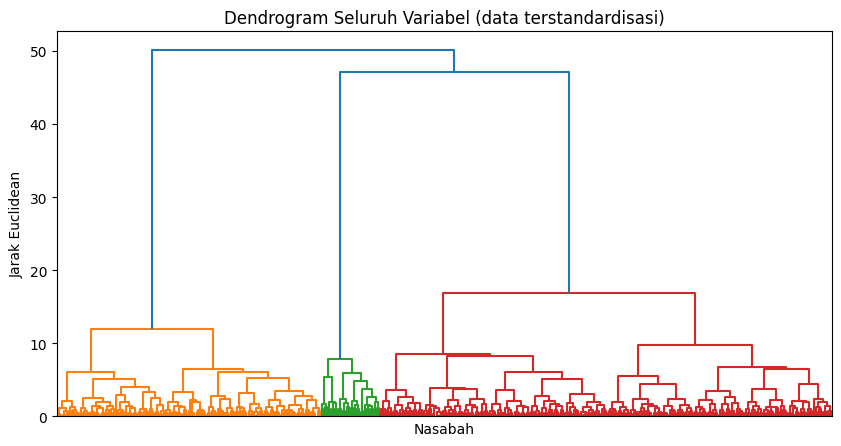

In [6]:
# Standardisasi agar seluruh variabel berada pada skala yang sebanding
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_all)

# Dendrogram dari data terstandardisasi
Z = sch.linkage(X_scaled, method='ward')

plt.figure(figsize=(10, 5))
sch.dendrogram(Z, no_labels=True)
plt.title('Dendrogram Seluruh Variabel (data terstandardisasi)')
plt.xlabel('Nasabah')
plt.ylabel('Jarak Euclidean')
plt.show()

> `StandardScaler()` mengubah tiap variabel supaya rata-ratanya 0 dan simpangan bakunya 1, sehingga `Avg_Credit_Limit` tidak lagi mendominasi jarak. Ini penting karena tanpanya model hanya akan terbelah berdasarkan limit kredit saja. `sch.linkage(..., method='ward')` menghitung hierarki penggabungan dan `sch.dendrogram()` menggambarnya; `no_labels=True` dipakai karena 660 label akan bertumpuk dan tidak terbaca. Jarak penggabungan melonjak dari sekitar 16,8 ke 47,1, jadi memotong dendrogram di kisaran 20-40 menghasilkan 3 klaster (cabang oranye, hijau, dan merah).

---

# **Langkah 5 - Menentukan Jumlah Klaster Terbaik**

---

In [7]:
hasil = []

for k in range(2, 6):
    hc = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage='ward')
    label = hc.fit_predict(X_scaled)
    hasil.append([k, silhouette_score(X_scaled, label), davies_bouldin_score(X_scaled, label)])

pd.DataFrame(hasil, columns=['k', 'Silhouette', 'DBI']).round(4)

,k,Silhouette,DBI
0,2,0.4177,0.9326
1,3,0.5148,0.6810
2,4,0.3481,1.1493
3,5,0.2569,1.3851


> Tabel ini membandingkan k = 2 sampai 5, sejalan dengan siku dendrogram. Silhouette tertinggi (`0.5148`) dan DBI terendah (`0.6810`) sama-sama ada di k = 3, jadi k = 3 yang dipakai. Hasilnya juga masuk akal secara bisnis: segmen limit rendah, menengah, dan tinggi.

---

# **Langkah 6 - Model Agglomerative dan Scatterplot**

---

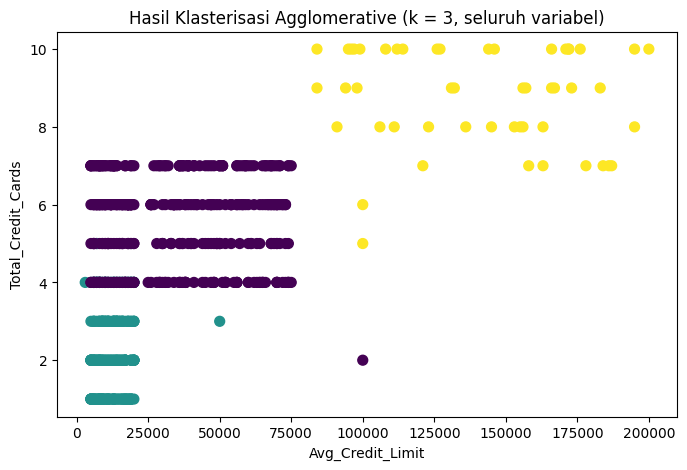

In [8]:
# Model Agglomerative dengan seluruh variabel dan k terbaik
hc = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
cluster_hc = hc.fit_predict(X_scaled)

plt.figure(figsize=(8, 5))
plt.scatter(X['Avg_Credit_Limit'], X['Total_Credit_Cards'], c=cluster_hc, s=50, cmap='viridis')

plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('Hasil Klasterisasi Agglomerative (k = 3, seluruh variabel)')
plt.show()

> Model dilatih di lima variabel terstandardisasi, lalu hasilnya divisualisasikan di dua variabel supaya bisa dibaca. Terbentuk 3 klaster: 385 nasabah dengan limit rata-rata 33.852 (2-7 kartu), 225 nasabah dengan limit rata-rata 12.151 (1-5 kartu), dan 50 nasabah dengan limit rata-rata 141.040 (5-10 kartu). Pemisahan di plot tidak sepenuhnya rapi karena `Total_visits_bank`, `Total_visits_online`, dan `Total_calls_made` juga ikut menentukan klaster, padahal tidak tergambar di sini. Warna hanya penanda label klaster, bukan urutan peringkat.

---

# **Langkah 7 - Evaluasi Model**

---

In [9]:
print(f'Silhouette Score Agglomerative: {silhouette_score(X_scaled, cluster_hc)}')
print(f'Davies-Bouldin Index Agglomerative: {davies_bouldin_score(X_scaled, cluster_hc)}')

Silhouette Score Agglomerative: 0.5147639589977819
Davies-Bouldin Index Agglomerative: 0.680959518994733


> Silhouette `0.5148` dan DBI `0.6810`. Silhouette di atas 0.5 berarti mayoritas nasabah lebih dekat ke klasternya sendiri, dan DBI di bawah 1 menandakan klaster masih cukup terpisah. Angkanya tidak setinggi K-Means di JS07 (0.719) karena di sini kelima variabel dipakai sekaligus dan datanya sudah distandardisasi, jadi ruang perhitungannya berbeda dan tidak bisa dibandingkan langsung.

> Kesimpulan Tugas Lab 1: dengan seluruh variabel terstandardisasi, Agglomerative Clustering menghasilkan 3 segmen nasabah (limit rendah, menengah, tinggi) dengan Silhouette 0.5148 dan DBI 0.6810.